# 第 42 课｜mplfinance K 线、指标与信号标注

本 Notebook 对应「365 天量化金融」第 42 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里将课程 API 重建为可离线执行、可核对的量化教学实现，并补充数据契约、断言与方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/42_youtube-xvHD9f4vHEE/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情（**非真实股票数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **来源边界**：课程材料没有提供可独立核验的完整源码和真实行情快照。本 Notebook 复现课程方法，不复述视频中真实股票的价格结论。

## 1. 本节量化问题

第 41 课用 Plotly 逐层搭交互图；本课改用专门面向 OHLCV 的 `mplfinance`，快速生成适合复盘归档的静态 K 线。

课程主线：

1. `mpf.plot(..., type="candle")` 画 K 线；
2. `mav=(5, 20, 60)` 与 `volume=True` 加均线和成交量；
3. `make_addplot` 叠加布林带与金叉/死叉；
4. `style` 和 `savefig` 生成高清图片；
5. 通过一个最小回测诊断说明：把交叉点画出来，不等于策略可盈利。

## 2. 输入、输出与验收

**输入**：`daily_prices.csv` 中虚构资产 `EV_A` 最近 220 个交易日。

**输出**

- 完整 K 线、5/20/60 日均线与成交量；
- 20 日布林带；
- 5/20 日金叉、死叉标记；
- `outputs/42_mplfinance_review.png` 高清静态图；
- 信号次数、换手与交易成本拖累的诊断表。

**验收**

- `DatetimeIndex` 唯一、升序；列名严格为 `Open/High/Low/Close/Volume`；
- OHLC 关系合法；
- 信号只在均线形成后出现，并保持原日期索引；
- 当日收盘生成信号，仓位从下一交易日收益开始生效；
- 输出图片存在且可读取。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# 本课新增 mplfinance；Image 用于在静态报告中显示已保存图片。
import mplfinance as mpf
from IPython.display import Image, display

print("mplfinance:", mpf.__version__)

mplfinance: 0.12.10b0


## 3. 准备 mplfinance 数据契约

`mplfinance` 默认要求：

- 行索引是升序 `DatetimeIndex`；
- 列名为 `Open/High/Low/Close/Volume`；
- 每一行是一根同频率 K 线。

大小写、日期类型或排序错误都会导致报错或错图。

In [3]:
# 从完整模拟长表筛选单资产，并严格改成 mplfinance 所需列名。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
price = (
    daily.loc[
        daily["symbol"].eq("EV_A"),
        ["date", "open", "high", "low", "close", "volume"],
    ]
    .sort_values("date")
    .set_index("date")
    .rename(
        columns={
            "open": "Open",
            "high": "High",
            "low": "Low",
            "close": "Close",
            "volume": "Volume",
        }
    )
    .tail(220)
)

print("shape:", price.shape, "含义: 日期 × OHLCV")
print("区间:", price.index.min().date(), "→", price.index.max().date())
display(price.head(3))
display(price.tail(3))

assert isinstance(price.index, pd.DatetimeIndex)
assert price.index.is_unique and price.index.is_monotonic_increasing
assert price.columns.tolist() == ["Open", "High", "Low", "Close", "Volume"]
assert (price["High"] >= price[["Open", "Close"]].max(axis=1)).all()
assert (price["Low"] <= price[["Open", "Close"]].min(axis=1)).all()
assert price["Volume"].ge(0).all()

shape: (220, 5) 含义: 日期 × OHLCV
区间: 2025-01-22 → 2025-11-25


,Open,High,Low,Close,Volume
date,,,,,
2025-01-22,30.0633,30.1906,29.7133,29.8396,2166587
2025-01-23,29.8035,30.3113,29.5879,30.0936,2143039
2025-01-24,30.1293,30.6396,29.9293,30.4376,4686238


,Open,High,Low,Close,Volume
date,,,,,
2025-11-21,42.9352,43.2227,41.7473,42.0288,2828482
2025-11-24,42.0224,42.2802,41.4361,41.6918,3118668
2025-11-25,41.6482,41.8792,40.2380,40.4624,4571272


## 4. 一行接口：K 线、均线和成交量

`mav=(5, 20, 60)` 表示三条简单移动平均线；它们由收盘价计算。`volume=True` 创建成交量副图。`returnfig=True` 返回 Figure/Axes，便于继续加工和测试。

In [4]:
# 采用 A 股常见的红涨绿跌配色，并获得 Figure 供后续检查。
market_colors = mpf.make_marketcolors(
    up="#d62728",
    down="#2ca02c",
    edge="inherit",
    wick="inherit",
    volume="inherit",
)
course_style = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=market_colors,
    rc={"font.family": chinese_font},
)

basic_fig, basic_axes = mpf.plot(
    price,
    type="candle",
    mav=(5, 20, 60),
    volume=True,
    style=course_style,
    title="EV_A 模拟行情｜K 线 + MAV + 成交量",
    ylabel="模拟价格",
    ylabel_lower="成交量",
    returnfig=True,
    figsize=(12, 7),
)

print("Axes 数量:", len(basic_axes))
assert len(basic_axes) >= 2
plt.close(basic_fig)

Axes 数量: 4


## 5. 布林带：先准确写出公式

20 日布林带（Bollinger Bands）的常见定义：

\[
Middle_t = SMA_{20}(t)
\]

\[
Upper_t = Middle_t + 2\sigma_{20}(t),\quad
Lower_t = Middle_t - 2\sigma_{20}(t)
\]

这里 pandas `std()` 默认 `ddof=1`（样本标准差）。窗口 20、倍数 2 只是惯例，不是自然定律；价格触轨也不是确定性买卖信号。

In [5]:
# 计算 20 日中轨与样本标准差，再得到上下轨；前 19 日保持 NaN。
middle = price["Close"].rolling(20, min_periods=20).mean()
rolling_std = price["Close"].rolling(20, min_periods=20).std(ddof=1)
bollinger = pd.DataFrame(
    {
        "Middle": middle,
        "Upper": middle + 2 * rolling_std,
        "Lower": middle - 2 * rolling_std,
    },
    index=price.index,
)

display(bollinger.dropna().head(3).round(4))

assert bollinger.iloc[:19].isna().all().all()
assert (bollinger["Upper"].dropna() >= bollinger["Middle"].dropna()).all()
assert (bollinger["Middle"].dropna() >= bollinger["Lower"].dropna()).all()

,Middle,Upper,Lower
date,,,
2025-02-18,31.4856,33.5253,29.4459
2025-02-19,31.6815,33.8060,29.5569
2025-02-20,31.8691,34.0646,29.6735


## 6. 金叉与死叉：条件和时点

令快线为 5 日 SMA、慢线为 20 日 SMA：

- 金叉：今日 `SMA5 > SMA20`，昨日 `SMA5 <= SMA20`；
- 死叉：今日 `SMA5 < SMA20`，昨日 `SMA5 >= SMA20`。

信号本身落在计算完成的收盘日。若策略使用当日收盘价生成信号，不能再让该仓位赚取同一日收益；下面把仓位延迟一期。

In [6]:
# 先计算均线和“快线在慢线上方”的状态，再检测状态切换。
signals = pd.DataFrame(index=price.index)
signals["SMA5"] = price["Close"].rolling(5, min_periods=5).mean()
signals["SMA20"] = price["Close"].rolling(20, min_periods=20).mean()
signals["above"] = signals["SMA5"].gt(signals["SMA20"])
prior_above = signals["above"].shift(1, fill_value=False)
signals["golden_cross"] = signals["above"] & ~prior_above
signals["death_cross"] = ~signals["above"] & prior_above

# 长期均线尚未形成的日期不允许出现交叉信号。
valid_signal_window = signals["SMA20"].notna()
signals.loc[~valid_signal_window, ["golden_cross", "death_cross"]] = False

signal_dates = pd.concat(
    [
        signals.loc[signals["golden_cross"], ["SMA5", "SMA20"]].assign(事件="金叉"),
        signals.loc[signals["death_cross"], ["SMA5", "SMA20"]].assign(事件="死叉"),
    ]
).sort_index()

print("金叉次数:", int(signals["golden_cross"].sum()))
print("死叉次数:", int(signals["death_cross"].sum()))
display(signal_dates.head(10).round(4))

assert not (signals["golden_cross"] & signals["death_cross"]).any()
assert not signals.iloc[:19][["golden_cross", "death_cross"]].any().any()
assert signal_dates.index.isin(price.index).all()

金叉次数: 6
死叉次数: 6


,SMA5,SMA20,事件
date,,,
2025-02-18,32.6816,31.4856,金叉
2025-04-24,39.4011,39.4345,死叉
2025-05-13,38.8949,38.6382,金叉
2025-06-06,39.7700,39.9253,死叉
2025-06-17,39.8784,39.7925,金叉
2025-07-15,42.4432,42.4925,死叉
2025-07-31,42.3814,42.1055,金叉
2025-09-16,44.7589,45.2748,死叉
2025-09-26,45.5857,45.4556,金叉


## 7. `make_addplot`：指标和信号保持原日期索引

`make_addplot` 接受与主表等长、同索引的序列。没有信号的日期用 `NaN`，而不是删行；否则标记会落到错误日期。

金叉三角放在当日最低价下方，死叉三角放在最高价上方。它们是**信号发现日**标记，不声称可以在同一收盘价成交。

In [7]:
# 用 NaN 保留完整日期轴，只在信号日生成三角标记位置。
golden_marker = pd.Series(np.nan, index=price.index, name="金叉")
death_marker = pd.Series(np.nan, index=price.index, name="死叉")
golden_marker.loc[signals["golden_cross"]] = (
    price.loc[signals["golden_cross"], "Low"] * 0.97
)
death_marker.loc[signals["death_cross"]] = (
    price.loc[signals["death_cross"], "High"] * 1.03
)

add_plots = [
    mpf.make_addplot(bollinger["Middle"], color="#2f4f4f", width=1.0),
    mpf.make_addplot(bollinger["Upper"], color="#6a5acd", width=0.8),
    mpf.make_addplot(bollinger["Lower"], color="#6a5acd", width=0.8),
    mpf.make_addplot(
        golden_marker,
        type="scatter",
        marker="^",
        markersize=70,
        color="#d62728",
    ),
    mpf.make_addplot(
        death_marker,
        type="scatter",
        marker="v",
        markersize=70,
        color="#2ca02c",
    ),
]

assert golden_marker.notna().sum() == signals["golden_cross"].sum()
assert death_marker.notna().sum() == signals["death_cross"].sum()
pd.testing.assert_index_equal(golden_marker.index, price.index)

## 8. 高清导出并显示

`savefig` 中的 `dpi=160` 控制像素密度，`bbox_inches="tight"` 减少多余边缘。保存后关闭 Figure，避免批量生成报告时积累内存。

已写入: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain/outputs/42_mplfinance_review.png
文件大小: 199.3 KiB


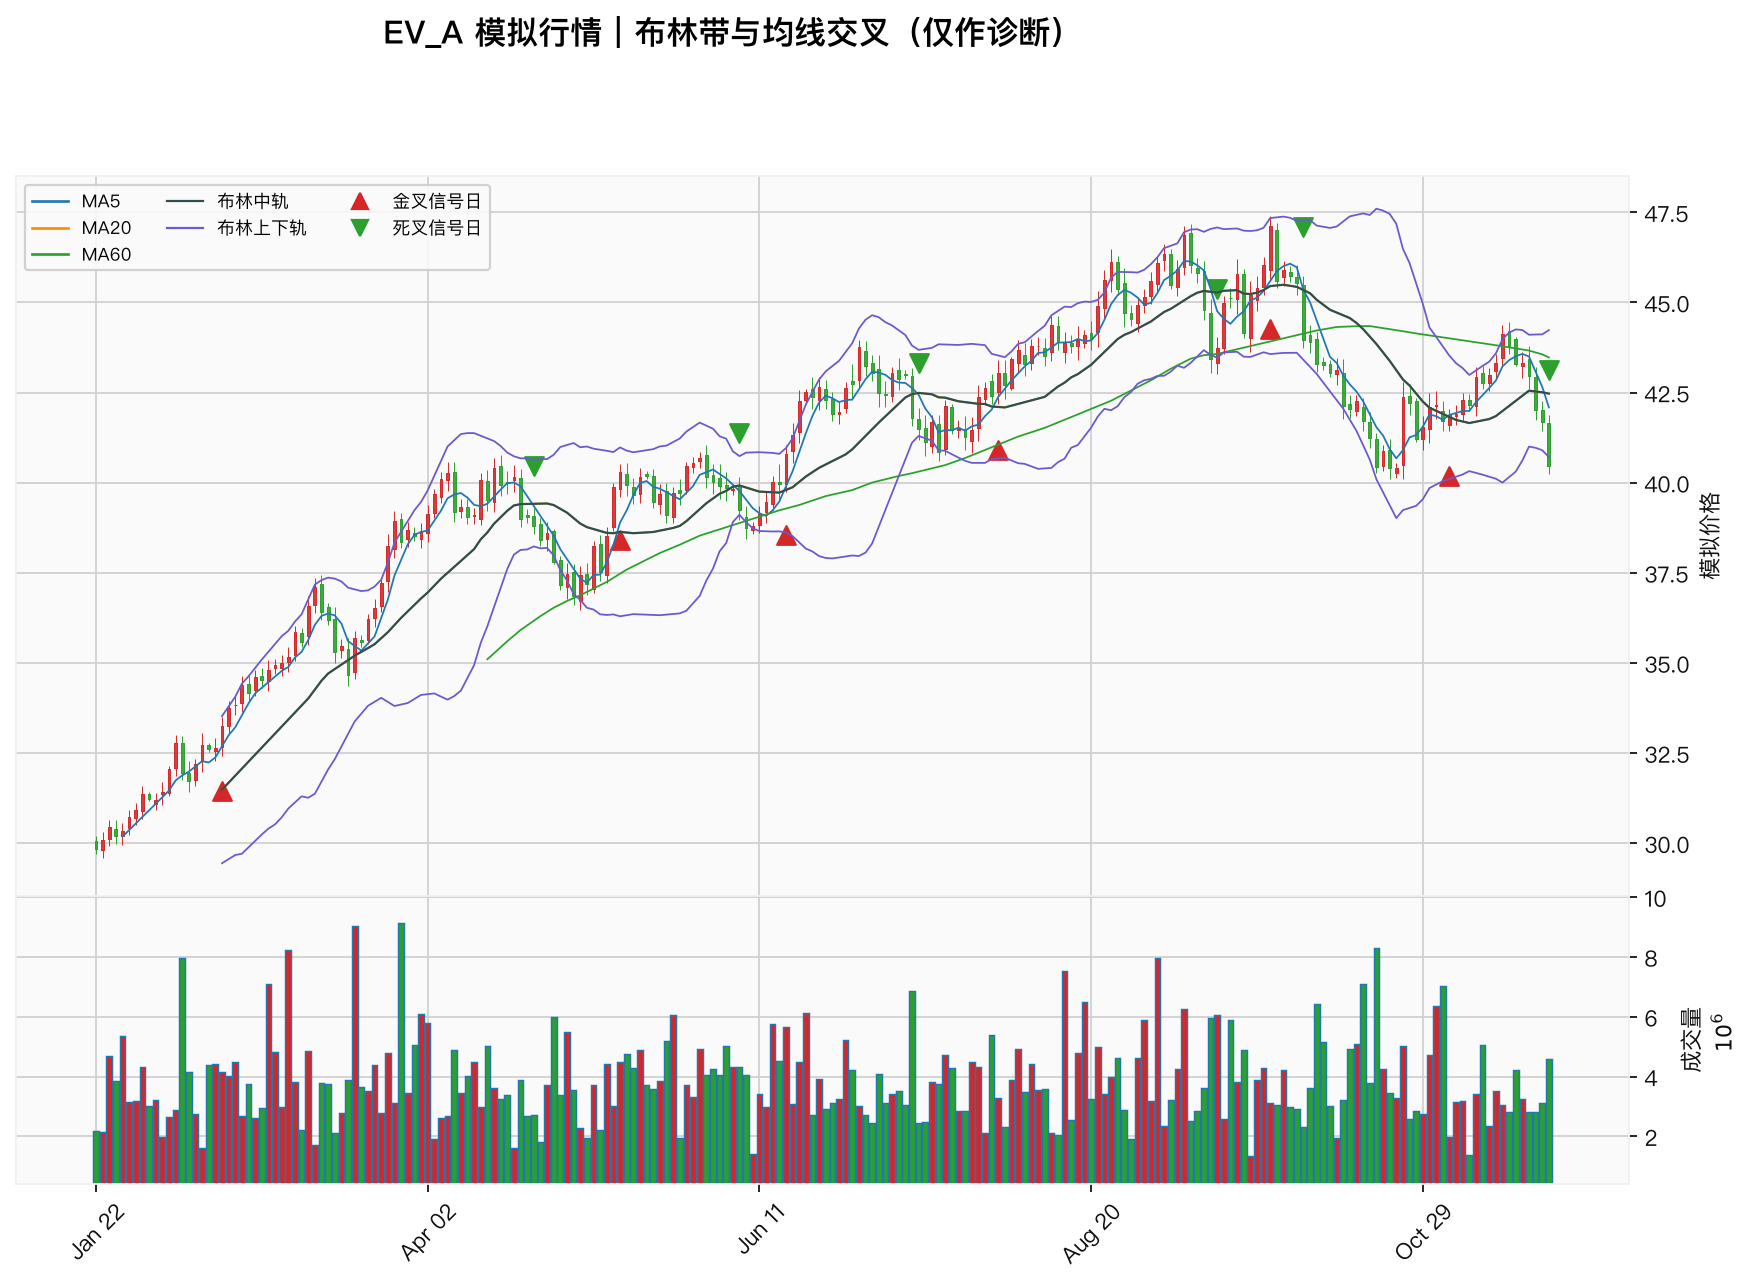

In [8]:
# 生成课程成品图；使用 addplot 叠加布林带和交叉信号。
from matplotlib.lines import Line2D

image_path = OUTPUT_DIR / "42_mplfinance_review.png"
review_fig, review_axes = mpf.plot(
    price,
    type="candle",
    mav=(5, 20, 60),
    mavcolors=("#1f77b4", "#ff8c00", "#2ca02c"),
    volume=True,
    addplot=add_plots,
    style=course_style,
    title="EV_A 模拟行情｜布林带与均线交叉（仅作诊断）",
    ylabel="模拟价格",
    ylabel_lower="成交量",
    returnfig=True,
    figsize=(14, 9),
    warn_too_much_data=500,
)

# mplfinance 不会自动为全部 addplot 生成易读图例，因此显式说明每条线和信号。
legend_handles = [
    Line2D([0], [0], color="#1f77b4", lw=1.2, label="MA5"),
    Line2D([0], [0], color="#ff8c00", lw=1.2, label="MA20"),
    Line2D([0], [0], color="#2ca02c", lw=1.2, label="MA60"),
    Line2D([0], [0], color="#2f4f4f", lw=1.0, label="布林中轨"),
    Line2D([0], [0], color="#6a5acd", lw=1.0, label="布林上下轨"),
    Line2D(
        [0], [0], marker="^", color="none", markerfacecolor="#d62728",
        markeredgecolor="#d62728", markersize=7, label="金叉信号日"
    ),
    Line2D(
        [0], [0], marker="v", color="none", markerfacecolor="#2ca02c",
        markeredgecolor="#2ca02c", markersize=7, label="死叉信号日"
    ),
]
review_axes[0].legend(
    handles=legend_handles,
    loc="upper left",
    ncol=3,
    fontsize=8,
    framealpha=0.88,
)

review_fig.savefig(image_path, dpi=160, bbox_inches="tight")
plt.close(review_fig)

print("已写入:", image_path)
print("文件大小:", round(image_path.stat().st_size / 1024, 1), "KiB")
assert image_path.exists()
assert image_path.stat().st_size > 50_000

display(Image(filename=str(image_path)))

## 9. 别把“画出信号”误当成“验证策略”

下面只做一个时序和成本诊断：

- 日收益：`Close.pct_change()`；
- 决策状态：快线在慢线上方；
- 执行仓位：决策状态 `shift(1)`，从下一日收益开始生效；
- 换手：仓位绝对变化；
- 成本：每次仓位变化按 10 bp（0.10%）扣减。

这仍不是完整 A 股回测：没有滑点、涨跌停、停牌、T+1、手续费最低额或复权事件。

In [9]:
# 用下一期仓位避免同日收盘信号偷取同日收益，并量化换手成本拖累。
diagnostic = pd.DataFrame(index=price.index)
diagnostic["asset_return"] = price["Close"].pct_change(fill_method=None)
diagnostic["decision"] = signals["above"].astype(float)
diagnostic["position"] = diagnostic["decision"].shift(1, fill_value=0.0)
diagnostic["turnover"] = diagnostic["position"].diff().abs().fillna(
    diagnostic["position"].abs()
)
diagnostic["gross_return"] = (
    diagnostic["position"] * diagnostic["asset_return"].fillna(0.0)
)
cost_rate = 0.001
diagnostic["net_return"] = (
    diagnostic["gross_return"] - diagnostic["turnover"] * cost_rate
)
diagnostic["gross_nav"] = (1 + diagnostic["gross_return"]).cumprod()
diagnostic["net_nav"] = (1 + diagnostic["net_return"]).cumprod()

summary = pd.Series(
    {
        "信号切换次数": int(diagnostic["turnover"].gt(0).sum()),
        "累计换手": diagnostic["turnover"].sum(),
        "期末毛净值": diagnostic["gross_nav"].iloc[-1],
        "期末净净值": diagnostic["net_nav"].iloc[-1],
        "成本拖累": diagnostic["gross_nav"].iloc[-1] - diagnostic["net_nav"].iloc[-1],
    },
    name="诊断结果",
)
display(summary.to_frame().round(6))

assert diagnostic["position"].iloc[0] == 0.0
assert diagnostic["gross_nav"].gt(0).all()
assert diagnostic["net_nav"].gt(0).all()
assert diagnostic["net_nav"].iloc[-1] <= diagnostic["gross_nav"].iloc[-1] + 1e-12

,诊断结果
信号切换次数,11.000000
累计换手,11.000000
期末毛净值,1.059194
期末净净值,1.047578
成本拖累,0.011616


## 10. 量化意义与方法边界

- mplfinance 是 OHLCV 高层绘图工具；它减少样板代码，但不会验证复权、时区或可交易性。
- `mav` 是历史均线，不是未来预测；均线交叉在震荡期可能频繁反转并产生高换手。
- 布林带上/下轨是波动参照；触轨不等于必然反转。
- 图上的金叉/死叉是信号发现日，不等同于下单日和成交日。
- `Close`、`Open/High/Low` 必须使用兼容的复权口径，否则蜡烛结构会失真。
- 模拟数据只验证代码和时序；不能推断真实市场、真实证券或未来收益。
- 交易成本诊断不是完整回测，策略结论还需样本外、基准、参数稳定性和可执行性检验。

## 11. 可复用结论与练习

```text
OHLCV 契约 → 均线/布林带/事件计算
           → 同索引 NaN 信号序列 → make_addplot
           → 高清静态图 → 下一期执行与成本诊断
```

练习：

1. 将 5/20 日均线改为 10/60 日，比较信号次数、换手和成本拖累。
2. 将 `cost_rate` 设为 0、5 bp、20 bp，绘制净值差异。
3. 把信号标记从发现日改为下一交易日开盘执行日，并解释所需价格字段。
4. 把布林带参数从 `(20, 2)` 改为 `(40, 2.5)`，但不要用同一数据挑“最好看”的参数后宣称有效。